In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

# Ignore warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load your dataset
# Update the path to match your file name
df = pd.read_csv('./Exam_Score_Prediction.csv')

# Display basic info
print(f"Dataset shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"\nColumn names:")
print(df.columns.tolist())

Dataset shape: 20,000 rows, 13 columns

Column names:
['student_id', 'age', 'gender', 'course', 'study_hours', 'class_attendance', 'internet_access', 'sleep_hours', 'sleep_quality', 'study_method', 'facility_rating', 'exam_difficulty', 'exam_score']


In [3]:
# YOUR CODE HERE:
df.head(10)

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,2,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,3,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,4,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,5,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7
5,6,23,male,b.tech,3.48,65.4,yes,4.2,good,mixed,low,moderate,58.2
6,7,17,female,b.tech,1.35,69.0,yes,7.4,average,online videos,high,hard,53.7
7,8,22,male,b.sc,5.48,51.1,yes,8.2,poor,self-study,low,moderate,47.3
8,9,18,other,bca,2.89,92.0,yes,6.6,poor,self-study,low,easy,44.9
9,10,17,male,bba,6.77,44.8,yes,9.8,average,group study,high,moderate,77.7


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        20000 non-null  int64  
 1   age               20000 non-null  int64  
 2   gender            20000 non-null  object 
 3   course            20000 non-null  object 
 4   study_hours       20000 non-null  float64
 5   class_attendance  20000 non-null  float64
 6   internet_access   20000 non-null  object 
 7   sleep_hours       20000 non-null  float64
 8   sleep_quality     20000 non-null  object 
 9   study_method      20000 non-null  object 
 10  facility_rating   20000 non-null  object 
 11  exam_difficulty   20000 non-null  object 
 12  exam_score        20000 non-null  float64
dtypes: float64(4), int64(2), object(7)
memory usage: 2.0+ MB


In [5]:
df.describe()

,student_id,age,study_hours,class_attendance,sleep_hours,exam_score
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000
mean,10000.504600,20.473300,4.007604,70.017365,7.00856,62.513225
std,5773.654959,2.284458,2.308313,17.282262,1.73209,18.908491
min,1.000000,17.000000,0.080000,40.600000,4.10000,19.599000
25%,5000.750000,18.000000,2.000000,55.100000,5.50000,48.800000
50%,10000.500000,20.000000,4.040000,69.900000,7.00000,62.600000
75%,15000.250000,22.000000,6.000000,85.000000,8.50000,76.300000
max,20001.000000,24.000000,7.910000,99.400000,9.90000,100.000000


In [6]:
# Define your target variable
TARGET = 'exam_score'  # <-- UPDATE THIS!

# Basic statistics of target
print(f"Target Variable: {TARGET}")
print(f"\nBasic Statistics:")
print(df[TARGET].describe())

Target Variable: exam_score

Basic Statistics:
count    20000.000000
mean        62.513225
std         18.908491
min         19.599000
25%         48.800000
50%         62.600000
75%         76.300000
max        100.000000
Name: exam_score, dtype: float64


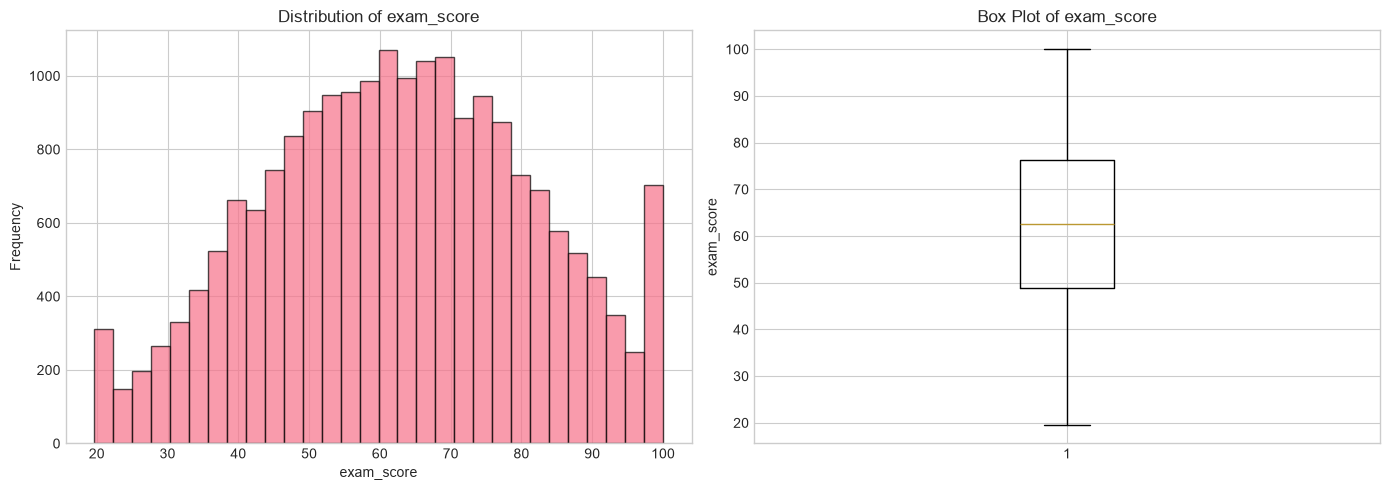


Skewness: -0.05
→ Target is approximately symmetric.


In [7]:
# Distribution of target variable
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df[TARGET].dropna(), bins=30, edgecolor='black', alpha=0.7)
axes[0].set_xlabel(TARGET)
axes[0].set_ylabel('Frequency')
axes[0].set_title(f'Distribution of {TARGET}')

# Box plot
axes[1].boxplot(df[TARGET].dropna())
axes[1].set_ylabel(TARGET)
axes[1].set_title(f'Box Plot of {TARGET}')

plt.tight_layout()
plt.show()

# Check skewness
skewness = df[TARGET].skew()
print(f"\nSkewness: {skewness:.2f}")
if abs(skewness) > 1:
    print("→ Target is highly skewed. Consider log transform in feature engineering.")
elif abs(skewness) > 0.5:
    print("→ Target is moderately skewed.")
else:
    print("→ Target is approximately symmetric.")

In [8]:
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates:,} ({(duplicates / len(df)) * 100:.2f}%)")

Duplicate rows: 0 (0.00%)


# Numerical Data Features

In [11]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numerical_cols.pop(-1)
numerical_cols
print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")

Numerical columns (5): ['student_id', 'age', 'study_hours', 'class_attendance', 'sleep_hours']


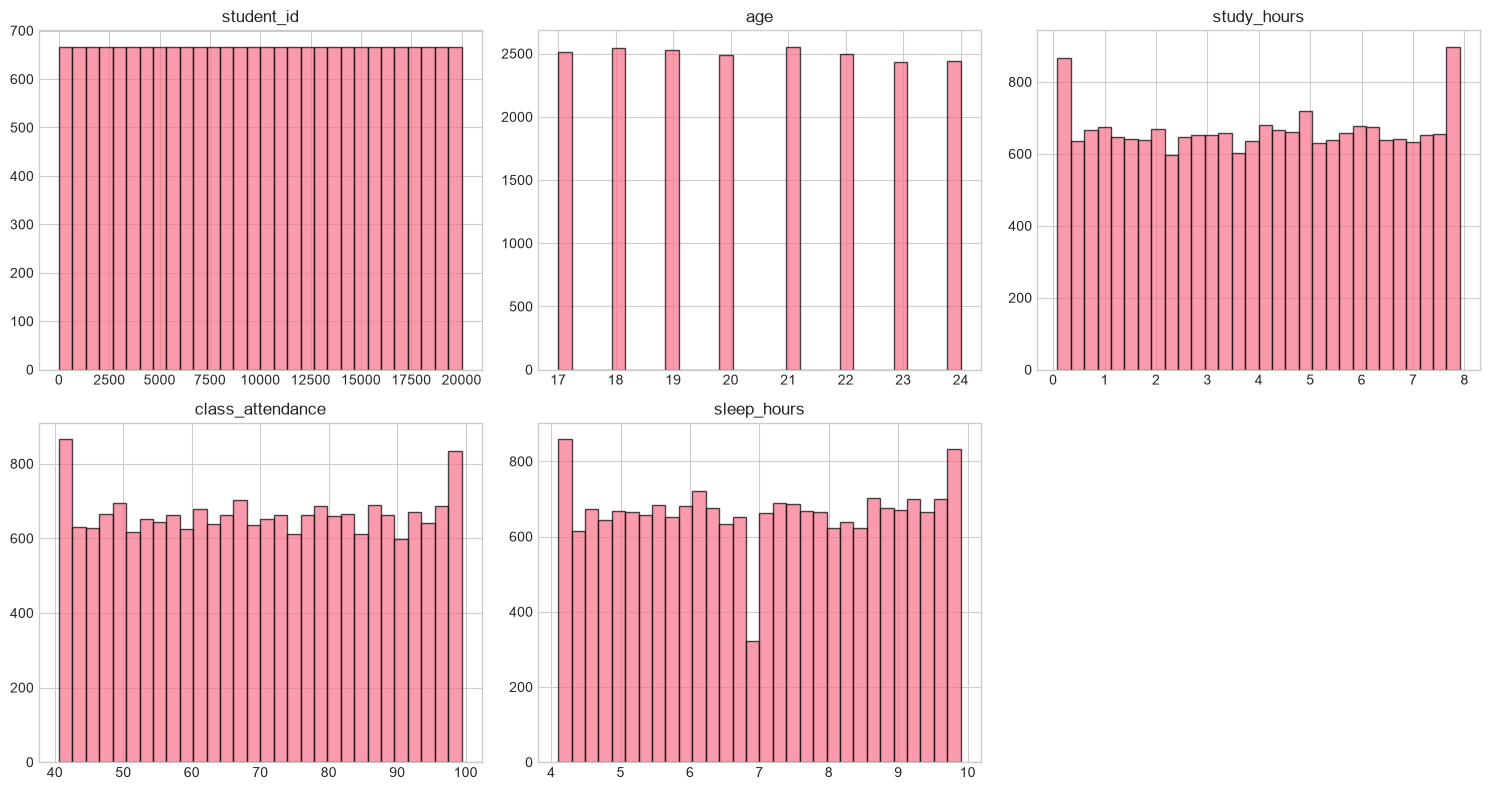

In [12]:
# Distribution of numerical features
if len(numerical_cols) > 0:
    n_cols = 3
    n_rows = (len(numerical_cols) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_rows == 1 and n_cols == 1 else axes

    for i, col in enumerate(numerical_cols):
        axes[i].hist(df[col].dropna(), bins=30, edgecolor='black', alpha=0.7)
        axes[i].set_title(col)
        axes[i].set_xlabel('')

    # Hide empty subplots
    for j in range(len(numerical_cols), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("No numerical features found (besides target).")

In [13]:

categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Categorical columns: {len(categorical_cols)}, {categorical_cols}")

for col in categorical_cols:
    print(f"Number of unique values for {col}: {df[col].nunique()}")
    print(f"{df[col].value_counts().head(10)}")
    print("")

Categorical columns: 7, ['gender', 'course', 'internet_access', 'sleep_quality', 'study_method', 'facility_rating', 'exam_difficulty']
Number of unique values for gender: 3
gender
other     6726
male      6695
female    6579
Name: count, dtype: int64

Number of unique values for course: 7
course
bca        2902
ba         2896
b.sc       2878
b.com      2864
bba        2836
diploma    2826
b.tech     2798
Name: count, dtype: int64

Number of unique values for internet_access: 2
internet_access
yes    16988
no      3012
Name: count, dtype: int64

Number of unique values for sleep_quality: 3
sleep_quality
average    6694
poor       6687
good       6619
Name: count, dtype: int64

Number of unique values for study_method: 5
study_method
self-study       4079
online videos    4069
coaching         4036
group study      3922
mixed            3894
Name: count, dtype: int64

Number of unique values for facility_rating: 3
facility_rating
medium    6760
low       6638
high      6602
Name: count,

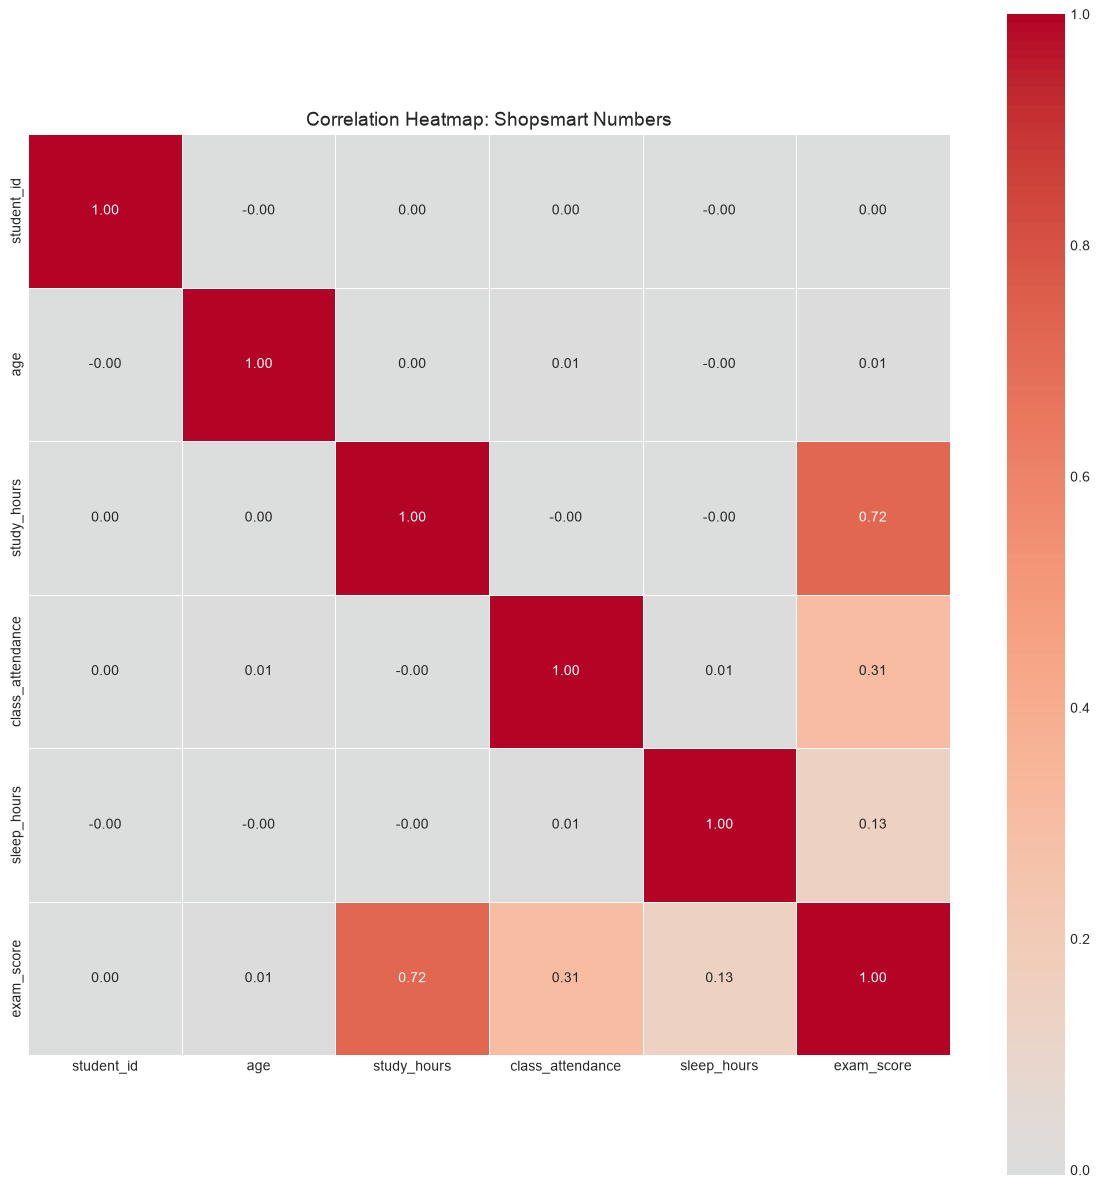

In [15]:
columns = numerical_cols + [TARGET]
correlation_matrix = df[columns].corr()

plt.figure(figsize=(12, 12))

# Select only numeric columns for correlation
numeric_df = df.select_dtypes(include=['number'])

# Create the heatmap
sns.heatmap(correlation_matrix, 
            annot=True,           # Show correlation values
            cmap='coolwarm',      # Red = positive, Blue = negative
            center=0,             # Center the colormap at 0
            fmt='.2f',            # 2 decimal places
            square=True,          # Make cells square
            linewidths=0.5)       # Add grid lines

plt.title('Correlation Heatmap: Shopsmart Numbers', fontsize=14)
plt.tight_layout()
plt.show()

In [16]:
column_to_remove = 'exam_score'

if column_to_remove in correlation_matrix.columns:
    correlation_matrix = correlation_matrix.drop(columns=[column_to_remove], index=[column_to_remove])
    print(f"Successfully dropped {column_to_remove}")
else:
    print(f"Column {column_to_remove} not found in matrix.")
# correlation_matrix.drop(columns=['exam_score'], index=['exam_score'], inplace=True)

for col in correlation_matrix:
    print(col)
    # Get correlations with target from the original dataframe
    target_correlations = df[numerical_cols].corrwith(df[TARGET]).sort_values(ascending=False)

    print("\nCorrelations with target variable:")
    print(target_correlations)

    # Identify features with strong correlation (> 0.5)
    strong_corr_features = target_correlations[abs(target_correlations) > 0.5].index.tolist()
    print(f"\nFeatures with strong correlation > 0.5: {strong_corr_features}")

Successfully dropped exam_score
student_id

Correlations with target variable:
study_hours         0.717788
class_attendance    0.308850
sleep_hours         0.133222
age                 0.006522
student_id          0.003269
dtype: float64

Features with strong correlation > 0.5: ['study_hours']
age

Correlations with target variable:
study_hours         0.717788
class_attendance    0.308850
sleep_hours         0.133222
age                 0.006522
student_id          0.003269
dtype: float64

Features with strong correlation > 0.5: ['study_hours']
study_hours

Correlations with target variable:
study_hours         0.717788
class_attendance    0.308850
sleep_hours         0.133222
age                 0.006522
student_id          0.003269
dtype: float64

Features with strong correlation > 0.5: ['study_hours']
class_attendance

Correlations with target variable:
study_hours         0.717788
class_attendance    0.308850
sleep_hours         0.133222
age                 0.006522
student_id   

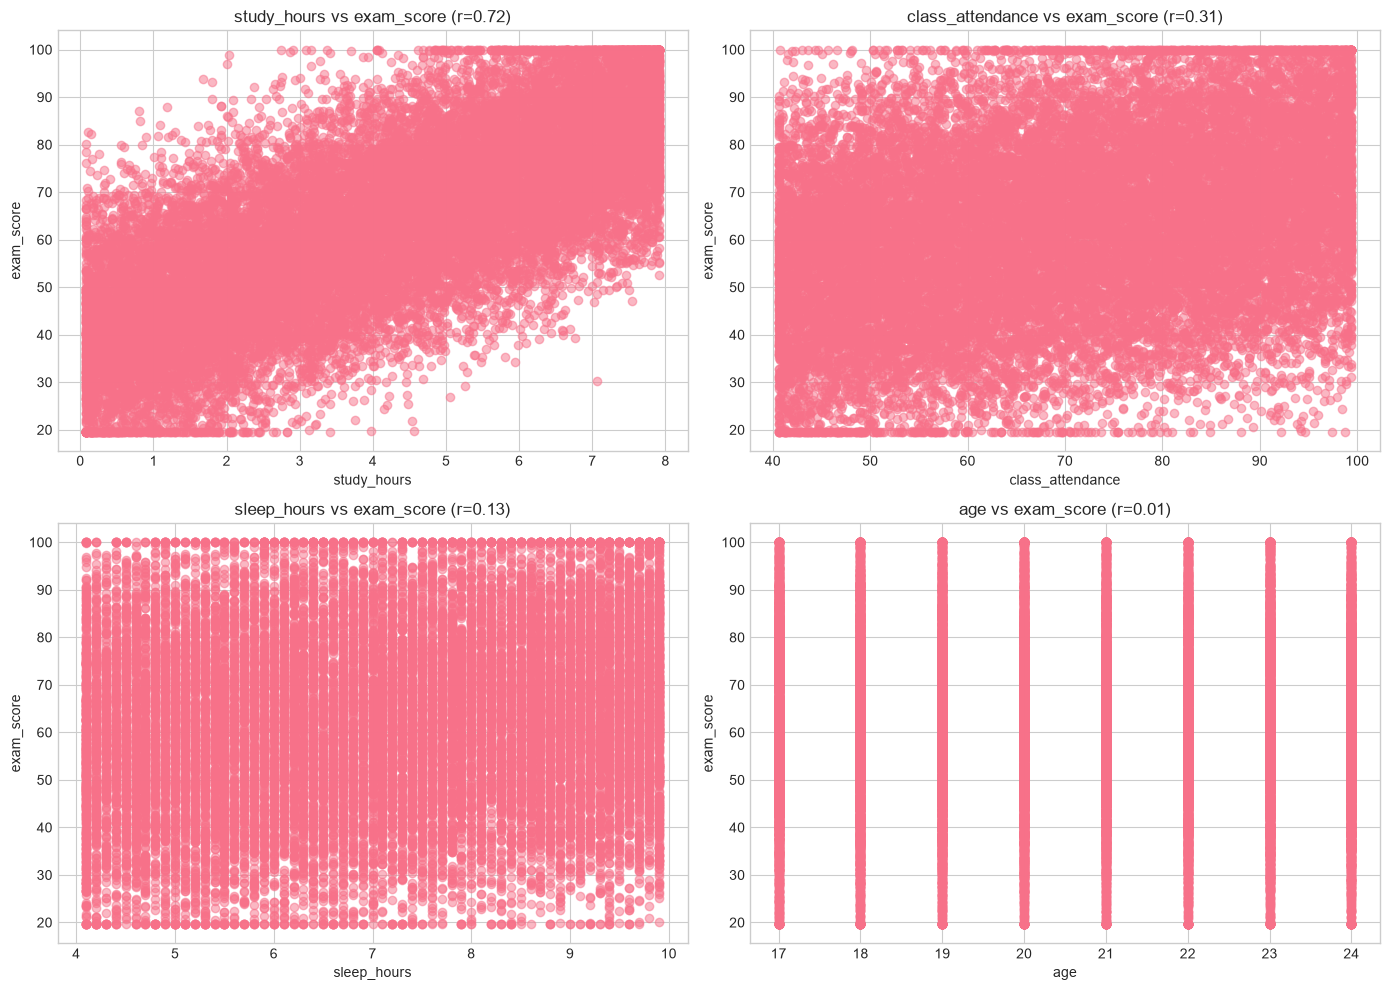

In [17]:
top_features = target_correlations.abs().sort_values(ascending=False).head(4).index.tolist()

if len(top_features) > 0:
    n_features = min(4, len(top_features))
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for i, feature in enumerate(top_features[:n_features]):
        axes[i].scatter(df[feature], df[TARGET], alpha=0.5)
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel(TARGET)
        corr = df[feature].corr(df[TARGET])
        axes[i].set_title(f'{feature} vs {TARGET} (r={corr:.2f})')

    # Hide unused subplots
    for j in range(n_features, 4):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("No numerical features to plot.")

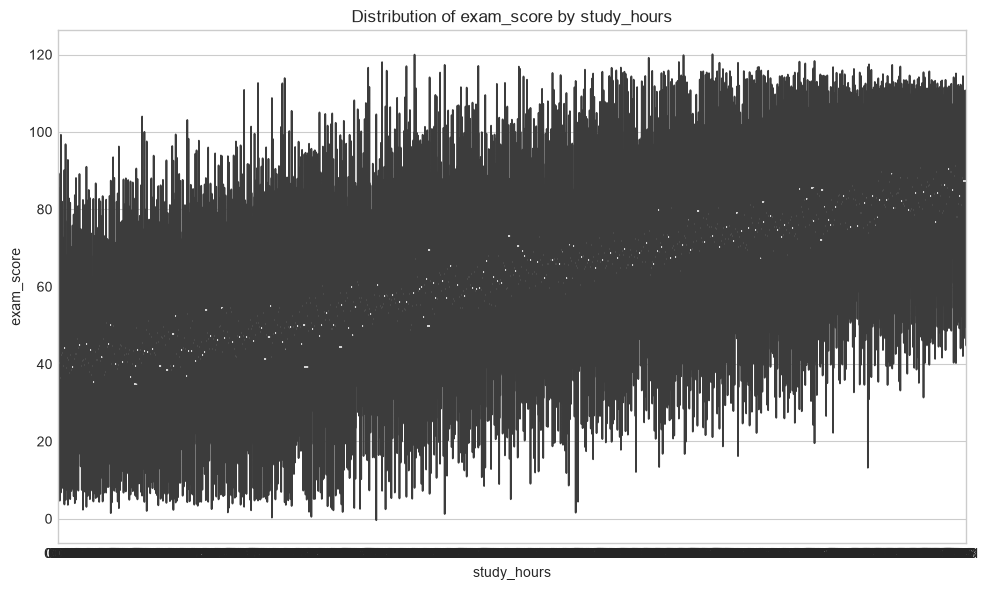

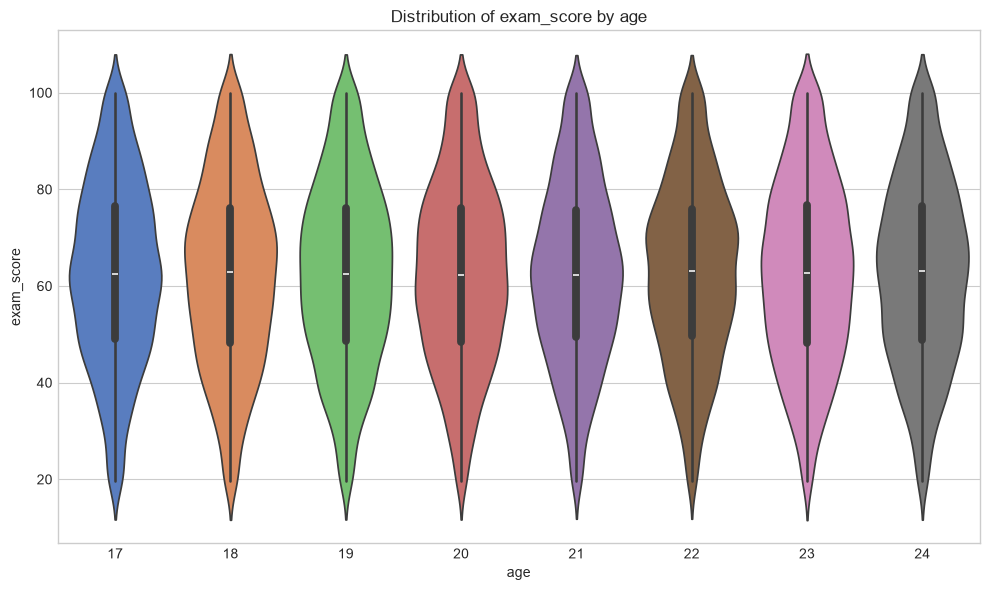

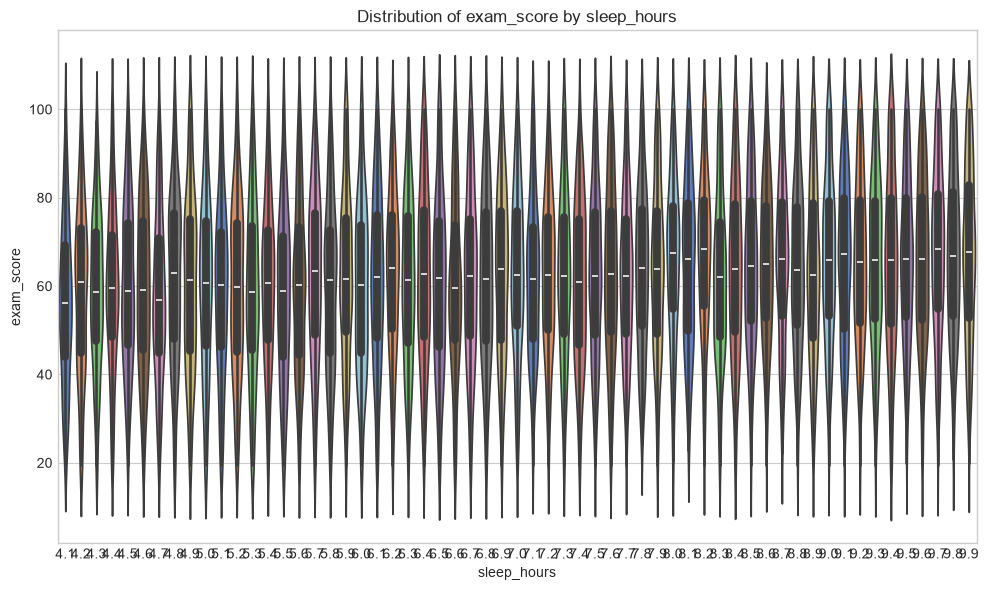

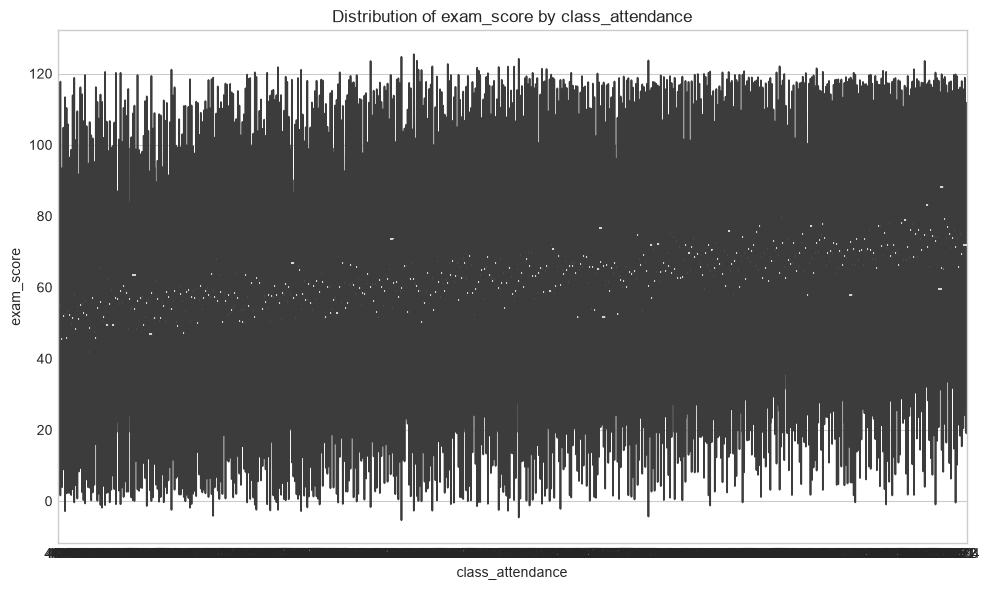

In [18]:
features = ['study_hours', 'age', 'sleep_hours', 'class_attendance']

# Assuming 'Category' is your feature and 'Target' is what you're predicting

if len(features) > 0:
    for i, feature in enumerate(features[:n_features]):
        plt.figure(figsize=(10, 6))
        sns.violinplot(data=df, x=feature, y='exam_score', palette="muted")
        plt.title(f'Distribution of {TARGET} by {feature}')
        plt.tight_layout()
        plt.show()

else:
    print("No numerical features to plot.")

In [20]:
key_features = features 
key_features

['study_hours', 'age', 'sleep_hours', 'class_attendance']

In [21]:
df[key_features]

,study_hours,age,sleep_hours,class_attendance
0,2.78,17,7.4,92.9
1,3.37,23,4.6,64.8
2,7.88,22,8.5,76.8
3,0.67,20,5.8,48.4
4,0.89,20,9.8,71.6
...,...,...,...,...
19995,6.50,18,5.0,71.3
19996,3.71,18,5.9,41.6
19997,7.88,19,4.6,68.2
19998,4.60,19,6.1,76.3


In [23]:
df_clean = df.copy()


print(f"Starting shape: {df_clean.shape}")

Starting shape: (20000, 13)


In [25]:
columns_to_drop = [
    'gender',
    'age',
    'student_id'
]

if columns_to_drop:
    df_clean = df_clean.drop(columns=columns_to_drop)
    print(f"Dropped {len(columns_to_drop)} columns: {columns_to_drop}")
    print(f"New shape: {df_clean.shape}")
else:
    print("No columns dropped. Update the list above if needed.")

Dropped 3 columns: ['gender', 'age', 'student_id']
New shape: (20000, 10)


In [29]:
def find_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    n_outliers = len(data[(data[column] < lower_bound) | (data[column] > upper_bound)])
    # print(f"{Q1} {Q3} for {column}, outliers: {n_outliers}")
    return n_outliers, lower_bound, upper_bound

# Get current numerical columns
current_numerical = df_clean.select_dtypes(include=[np.number]).columns.tolist()

print("Outlier analysis:")
print("="*60)
for col in current_numerical:
    n_outliers, lower, upper = find_outliers_iqr(df_clean, col)
    if n_outliers > 0:
        pct = n_outliers / len(df_clean) * 100
        print(f"{col}: {n_outliers:,} outliers ({pct:.1f}%) | bounds: [{lower:.2f}, {upper:.2f}]")

print("Current data types:")
print(df_clean.dtypes)


Outlier analysis:
Current data types:
course               object
study_hours         float64
class_attendance    float64
internet_access      object
sleep_hours         float64
sleep_quality        object
study_method         object
facility_rating      object
exam_difficulty      object
exam_score          float64
dtype: object


In [30]:
def label_encode_ordinal(df, column, order):
    df_encoded = df.copy()

    # Hint: Create a mapping dictionary like {'Bronze': 0, 'Silver': 1, ...}
    mapping = {}
    for index, item in enumerate(order):
        mapping[item] = index

    # Then use df_encoded[column].map(mapping)
    df_encoded[column] = df_encoded[column].map(mapping)

    return df_encoded


df_clean.info()

df_clean = label_encode_ordinal(df_clean, 'sleep_quality', ['poor', 'average', 'good'])
df_clean = label_encode_ordinal(df_clean, 'facility_rating', ['low', 'medium', 'high'])
df_clean = label_encode_ordinal(df_clean, 'exam_difficulty', ['hard', 'moderate', 'easy'])
df_clean = label_encode_ordinal(df_clean, 'internet_access', ['no', 'yes'])

cat_cols = ['study_method'] # df_clean.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Categorical columns to consider for encoding: {cat_cols}")
for col in cat_cols:
    n_unique = df_clean[col].nunique()
    recommendation = "one-hot encoding" if n_unique <= 10 else "consider label encoding or dropping"
    print(f"{col}: {n_unique} unique values → {recommendation}")

df_clean = pd.get_dummies(df_clean, columns=cat_cols)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   course            20000 non-null  object 
 1   study_hours       20000 non-null  float64
 2   class_attendance  20000 non-null  float64
 3   internet_access   20000 non-null  object 
 4   sleep_hours       20000 non-null  float64
 5   sleep_quality     20000 non-null  object 
 6   study_method      20000 non-null  object 
 7   facility_rating   20000 non-null  object 
 8   exam_difficulty   20000 non-null  object 
 9   exam_score        20000 non-null  float64
dtypes: float64(4), object(6)
memory usage: 1.5+ MB
Categorical columns to consider for encoding: ['study_method']
study_method: 5 unique values → one-hot encoding


In [31]:
df_clean.head()

,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,facility_rating,exam_difficulty,exam_score,study_method_coaching,study_method_group study,study_method_mixed,study_method_online videos,study_method_self-study
0,diploma,2.78,92.9,1,7.4,0,0,0,58.9,True,False,False,False,False
1,bca,3.37,64.8,1,4.6,1,1,1,54.8,False,False,False,True,False
2,b.sc,7.88,76.8,1,8.5,0,2,1,90.3,True,False,False,False,False
3,diploma,0.67,48.4,1,5.8,1,0,1,29.7,False,False,False,True,False
4,diploma,0.89,71.6,1,9.8,0,0,1,43.7,True,False,False,False,False


In [32]:
numerical_features = df_clean.select_dtypes(include=[np.number]).columns.tolist()
numerical_features.remove(TARGET)
print(f"Numerical features to consider for scaling: {numerical_features}")
for col in numerical_features:
    col_min = df_clean[col].min()
    col_max = df_clean[col].max()
    col_range = col_max - col_min
    print(f"{col}: min={col_min}, max={col_max}, range={col_range}")

Numerical features to consider for scaling: ['study_hours', 'class_attendance', 'internet_access', 'sleep_hours', 'sleep_quality', 'facility_rating', 'exam_difficulty']
study_hours: min=0.08, max=7.91, range=7.83
class_attendance: min=40.6, max=99.4, range=58.800000000000004
internet_access: min=0, max=1, range=1
sleep_hours: min=4.1, max=9.9, range=5.800000000000001
sleep_quality: min=0, max=2, range=2
facility_rating: min=0, max=2, range=2
exam_difficulty: min=0, max=2, range=2


In [33]:
df_clean.to_csv('./cleaned_data.csv', index=False)
print("✓ Cleaned data saved to ./cleaned_data.csv")

✓ Cleaned data saved to ./cleaned_data.csv
